<div style="background:linear-gradient(120deg,#EDE7FF 0%,#E3F0FF 55%,#E6FBF7 100%); color:#2A1B5C; padding:22px 26px; border-radius:14px; border:1px solid #DCD3FF; margin-bottom:8px;">

<h1 style="margin:0 0 6px 0; color:#3B1F7A">11 · Fine-tuning BERT vs BiomedBERT to read visit notes</h1>

<p style="margin:0 0 10px 0; font-size:1.1em; color:#4C3A8C">Level 5: transfer learning with Hugging Face, judged against the TF-IDF baseline</p>

| | |
|---|---|
| **Tasks** | ① **side-effect mode** (4 classes: none / concern / reported / negated) · ② **objections** (multi-label, 7 types) |
| **Data** | synthetic visit notes v1 (notebook 09): 738 train / 159 validation / 158 test |
| **Models** | TF-IDF + Logistic Regression (baseline) · `bert-base-uncased` · `BiomedBERT` |
| **Code** | `src/glp1_intel/models/finetune.py` (`python -m glp1_intel.models.finetune` runs everything, ~2 h on CPU) |
| **Concepts** | transfer learning · fine-tuning · classification head · Trainer · learning rate, warm-up, epochs, batch size, weight decay · early stopping · multi-label (sigmoid + BCE) · macro-F1 · bootstrap confidence intervals |

</div>

<div style="margin:6px 0 4px 0"><b>How to read this notebook:</b><br><span style="background:#F3EEFF; color:#3B1F7A; border-left:4px solid #8B5CF6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🟣 Section</span><span style="background:#FFF4E8; color:#7C2D12; border-left:4px solid #FB923C; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">💡 Concept</span><span style="background:#E9FBF8; color:#134E4A; border-left:4px solid #14B8A6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🛠️ What the next code does</span><span style="background:#EAF4FF; color:#1E3A8A; border-left:4px solid #3B82F6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">📊 Reading the output</span><span style="background:#FFF0F3; color:#881337; border-left:4px solid #F43F5E; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">⚠️ Watch out</span><span style="background:#EAFBF1; color:#065F46; border-left:4px solid #10B981; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🎯 Key takeaways</span></div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Transfer learning and fine-tuning</b>

Training a transformer from scratch needs billions of words and weeks of GPUs. **Transfer learning** reuses a model already **pre-trained** on huge text (notebook 10) and **fine-tunes** it on our small labelled set:
1. Keep all pre-trained layers (they already "understand" language).
2. Add a tiny **classification head** on top of the `[CLS]` vector: a single linear layer, initialised randomly. That's the "newly initialized" warning you see when loading.
3. Train **everything** for a few epochs with a **small learning rate**, so the pre-trained knowledge is adjusted, not destroyed (*catastrophic forgetting*).

That's why 738 notes are enough: the model already knows English (and, for BiomedBERT, medicine).

</div>

In [1]:
# ── Imports ─────────────────────────────────────────────────────────────────
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from glp1_intel import viz
from glp1_intel.viz import TEXT, TEXT_2, MUTED, subtitle
from glp1_intel.notebook_style import show
from glp1_intel.models import finetune as F

data = F.load()
MODEL_NAMES = {"tfidf": "TF-IDF + LogReg", "bert": "BERT (general)", "biomedbert": "BiomedBERT"}
COLORS = {"tfidf": MUTED, "bert": "#2a78d6", "biomedbert": "#7C5CFF"}

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 1 · The two tasks

</div>

In [2]:
tr = data["train"]
display(show(tr["ae_mode"].value_counts().rename_axis("side-effect mode").reset_index(name="train notes"),
             "Task ① classes (training set)"))
obj = pd.DataFrame({"objection": F.OBJ_LABELS, "train notes": [int(tr[f"obj_{k}"].sum()) for k in F.OBJ_LABELS]})
show(obj.assign(share=lambda d: 100 * d["train notes"] / len(tr)), "Task ② labels: one note can have several (or none)")

side-effect mode,train notes
none,281
concern,203
reported,170
negated,84


objection,train notes,share
cost_coverage,103,14.0
gi_tolerability,107,14.5
elderly_frailty,93,12.6
efficacy_vs_comp,99,13.4
injection_aversion,91,12.3
supply_access,90,12.2
safety_other,65,8.8


<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Single-label vs multi-label</b>

- **Single-label** (task ①): exactly one class per note → **softmax** over 4 classes + cross-entropy loss; prediction = the highest probability.
- **Multi-label** (task ②): each objection is its own yes/no → **sigmoid** per label + **binary cross-entropy**; prediction = every label with probability ≥ 0.5.
- **Macro-F1** averages F1 over classes equally, so the small "negated" class or rare objections count as much as common ones.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 2 · Training setup and hyper-parameters

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · What each setting does</b>

| Hyper-parameter | Value | Why |
|---|---|---|
| learning rate | 3e-5 | the standard BERT fine-tuning range (2e-5 to 5e-5): big enough to adapt, small enough not to forget |
| warm-up | first 10% of steps | ramps the learning rate up from 0 so the random head doesn't send huge gradients into pre-trained layers |
| epochs | 4 | small data; more epochs → overfitting |
| batch size | 16 | fits CPU memory; averages gradients over 16 notes |
| weight decay | 0.01 | mild regularisation (shrinks weights) |
| max length | 160 tokens | longest note is 168 tokens; padding is done **per batch** (*dynamic padding*), saving compute |
| early stopping | keep the epoch with the best **validation** macro-F1 | the test set is never used to choose anything |

`Trainer` (Hugging Face) handles the loop: batches → forward pass → loss → backward pass → optimiser step → evaluation each epoch.

</div>

In [3]:
# Results are cached: re-running this notebook loads them instead of retraining (~30 min per model on CPU).
# To retrain: delete reports/evaluation/nb11_*.json and run  python -m glp1_intel.models.finetune
results = {(t, m): F.result(t, m) for t in ["ae_mode", "objections"] for m in ["tfidf", "bert", "biomedbert"]}
missing = [k for k, v in results.items() if v is None]
print("Missing runs:", missing or "none")

Missing runs: none


<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 3 · Results: does fine-tuning beat the baseline?

</div>

In [4]:
rows = []
for (task, m), r in results.items():
    if r:
        rows.append({"task": task, "model": MODEL_NAMES[m], "test macro-F1": r["test"]["macro_f1"],
                     "95% CI low": r["ci95"][0], "95% CI high": r["ci95"][1],
                     "train minutes": r.get("train_minutes", 0)})
summary = pd.DataFrame(rows)
show(summary, "Test macro-F1 with bootstrap 95% confidence intervals (158 test notes)", precision=3)

task,model,test macro-F1,95% CI low,95% CI high,train minutes
ae_mode,TF-IDF + LogReg,0.860,0.782,0.925,0.000
ae_mode,BERT (general),0.971,0.935,0.995,32.500
ae_mode,BiomedBERT,0.939,0.895,0.975,26.000
objections,TF-IDF + LogReg,0.941,0.908,0.967,0.000
objections,BERT (general),0.849,0.801,0.890,23.400
objections,BiomedBERT,0.907,0.873,0.935,23.100


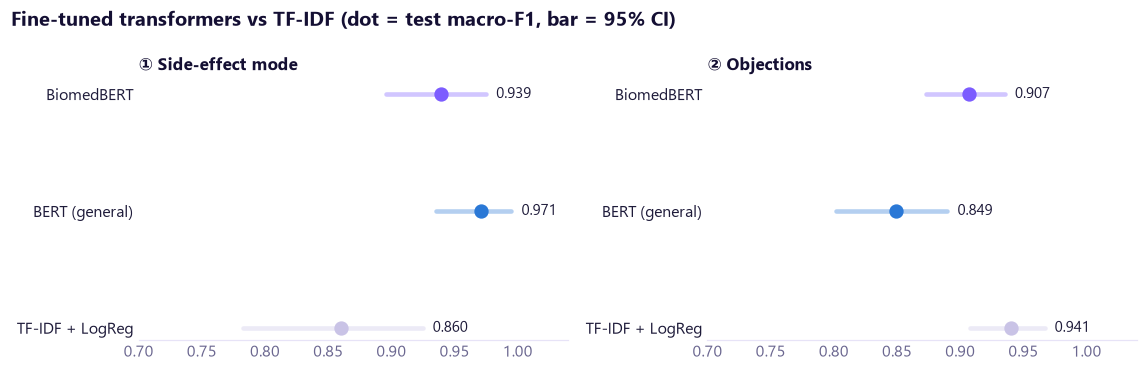

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4), sharex=True)
for ax, task, title in [(axes[0], "ae_mode", "① Side-effect mode"), (axes[1], "objections", "② Objections")]:
    sub = summary[summary["task"] == task].reset_index(drop=True)
    keys = [k for k, v in MODEL_NAMES.items() if v in set(sub["model"])]
    for y, k in enumerate(keys):
        r = sub[sub["model"] == MODEL_NAMES[k]].iloc[0]
        ax.plot([r["95% CI low"], r["95% CI high"]], [y, y], color=COLORS[k], lw=3, alpha=0.35, solid_capstyle="round")
        ax.scatter(r["test macro-F1"], y, color=COLORS[k], s=70, zorder=3)
        ax.text(r["95% CI high"] + 0.008, y, f"{r['test macro-F1']:.3f}", va="center", fontsize=9.5, color=TEXT)
    ax.set_yticks(range(len(keys)), [MODEL_NAMES[k] for k in keys])
    ax.set_title(title, fontsize=11, pad=8); ax.set_xlim(0.7, 1.04); ax.grid(axis="x")
fig.suptitle("Fine-tuned transformers vs TF-IDF (dot = test macro-F1, bar = 95% CI)", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=viz.INK)
fig.tight_layout()
viz.save(fig, "11_1_model_comparison")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **① Side-effect mode: the transformer clearly wins.** BERT reaches **0.971** macro-F1 vs **0.860** for TF-IDF, and their confidence intervals **don't overlap** (BERT's lower bound 0.94 is above TF-IDF's upper bound 0.93). BiomedBERT (0.939) also beats the baseline.
- **② Objections: TF-IDF wins (0.941)**, ahead of BiomedBERT (0.907) and BERT (0.849). Objections are expressed through **explicit keywords** (cost, PA, insurance, injections, elderly), exactly what bag-of-words is good at, and the transformers were still improving when training stopped (next section).
- **BERT vs BiomedBERT:** their intervals overlap on both tasks, so the data **can't name a winner** between them. A 110M-parameter model is not automatically better: it wins where **context** matters, not where keywords suffice.

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Bootstrap confidence intervals</b>

With only 158 test notes, one score is noisy. **Bootstrapping** resamples the test set 1,000 times (with replacement), recomputes macro-F1 each time and reports the middle 95% of those scores.
- Intervals that **don't overlap** → a real difference.
- Intervals that **overlap** → the data can't tell the models apart; don't claim a winner.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 4 · Learning curves: watching the model learn

</div>

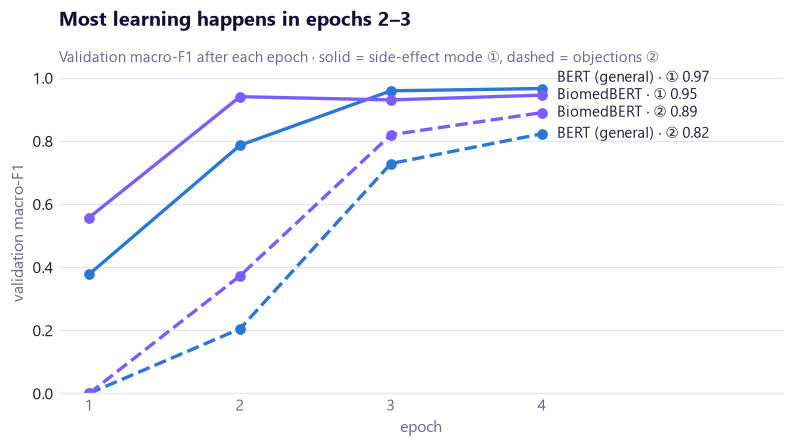

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
end_items = []
for (task, m), style in [(("ae_mode", "bert"), "-"), (("ae_mode", "biomedbert"), "-"),
                         (("objections", "bert"), "--"), (("objections", "biomedbert"), "--")]:
    r = results.get((task, m))
    if r and r["curve"]:
        c = pd.DataFrame(r["curve"])
        ax.plot(c["epoch"], c["val_macro_f1"], style, color=COLORS[m], marker="o", lw=2.2)
        end_items.append((f"{MODEL_NAMES[m]} · {'①' if task == 'ae_mode' else '②'} {c['val_macro_f1'].iloc[-1]:.2f}",
                          c["val_macro_f1"].iloc[-1]))
ax.set_xticks([1, 2, 3, 4]); ax.set_xlim(0.8, 5.6); ax.set_ylim(0, 1.02)
viz.end_labels(ax, 4.1, end_items, min_gap=0.055)                 # labels nudged apart, never overlapping
ax.set_xlabel("epoch"); ax.set_ylabel("validation macro-F1")
ax.grid(axis="y"); ax.grid(axis="x", visible=False)
ax.set_title("Most learning happens in epochs 2–3")
subtitle(ax, "Validation macro-F1 after each epoch · solid = side-effect mode ①, dashed = objections ②")
viz.save(fig, "11_2_learning_curves")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **Side-effect mode (solid):** both models jump between epochs 1 and 3, then flatten, so 4 epochs is enough. BiomedBERT starts faster (0.56 vs 0.38 after one epoch), consistent with its medical pre-training, but BERT catches up and ends slightly higher.
- **Objections (dashed):** both start near **0** (a multi-label head initially predicts "no" for everything) and are **still rising at epoch 4** (BiomedBERT 0.82 → 0.89). They're **under-trained**: more epochs (or a higher learning rate for the head) would very likely close the gap to TF-IDF. That's the first thing to try next, and an honest reason the baseline currently wins.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 5 · Where do the models still go wrong?

</div>

In [7]:
best_key = max(["bert", "biomedbert"], key=lambda m: results[("ae_mode", m)]["test"]["macro_f1"] if results.get(("ae_mode", m)) else -1)
rows = []
for m in ["tfidf", "bert", "biomedbert"]:
    r = results.get(("ae_mode", m))
    if r:
        rows.append({"model": MODEL_NAMES[m], **{c: r["test"]["per_class"][c]["f1-score"] for c in F.AE_LABELS}})
display(show(pd.DataFrame(rows), "Per-class F1 on side-effect mode (test)", precision=3))

cm = pd.DataFrame(results[("ae_mode", best_key)]["test"]["confusion"], index=F.AE_LABELS, columns=F.AE_LABELS)
show(cm.reset_index(names="true ↓ / predicted →"), f"Confusion matrix: {MODEL_NAMES[best_key]} (test)")

model,none,concern,reported,negated
TF-IDF + LogReg,0.955,0.917,0.902,0.667
BERT (general),0.971,0.979,0.988,0.944
BiomedBERT,0.962,0.925,0.950,0.919


true ↓ / predicted →,none,concern,reported,negated
none,51,1,0,2
concern,0,46,0,0
reported,0,1,40,0
negated,0,0,0,17


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- The big difference is the **negated** class (*"pts had no nausea"*): TF-IDF scores only **0.67**, the transformers **0.92–0.94**. Bag-of-words sees the word *nausea* in both reported and negated notes; a transformer reads **no** and **nausea** together in context, the negation problem from notebooks 06–07, solved.
- The confusion matrix shows the remaining mistakes are mostly between neighbouring meanings (concern ↔ reported, negated ↔ none), the genuinely ambiguous boundaries.

</div>

In [8]:
test = data["test"].copy()
test["pred_tfidf"] = [F.AE_LABELS[i] for i in results[("ae_mode", "tfidf")]["pred"]]
test["pred_best"] = [F.AE_LABELS[i] for i in results[("ae_mode", best_key)]["pred"]]
fixed = test[(test["pred_tfidf"] != test["ae_mode"]) & (test["pred_best"] == test["ae_mode"])]
still = test[test["pred_best"] != test["ae_mode"]]
display(show(fixed[["ae_mode", "pred_tfidf", "note"]].head(4), f"Notes TF-IDF got wrong but {MODEL_NAMES[best_key]} got right"))
show(still[["ae_mode", "pred_best", "note"]].head(6), f"Notes {MODEL_NAMES[best_key]} still gets wrong")

ae_mode,pred_tfidf,note
reported,negated,"Vis with NP, Ozempic top talker. Foundayo mentioned briefly. NP worried bout pancreatitis, thyroid issues, NAION risk, & patient pref for pills over injections. Said some dislike syringes. NP not keen, still leans on traditional OTH Rx. Noted one pt did see weight loss, but overall not swayed. NP suggests more time needed before considering switch."
negated,concern,"- HCP FP, Ozempic discussed - HCP: Patients no pancreatitis issues - HCP open but unsure - HCP: GI issues concern, but not major - Brief f/u needed post-next script - PA: Ensure comp scripts checked - GI: Follow up on GI concerns - HCP: Consider next month w/ new formulary info"
negated,none,"- HCP: Ozempic vs Zepbound - thinks Zepbound works as well - Pt: HCP mentions no nausea w/ Ozempic - F/U: HCP willing to prescribe if insurance covers - PA: Not an issue, covered by PPO - GI: No concerns about side effects - HCP: Ready to prescribe Ozempic next visit - W/: Schedule 1 mo f/u to review results"
negated,none,"Briefly met with Dr. from family practice on Ozempic and Rybelsus. Dr. mentioned Foundayo as an alternative but expressed concerns about cost and insurance coverage. Thought the competitor worked as well or better, but was open to considering it. Noted that patients using these GLP-1s reported no dizziness. Dr. seemed undecided, suggesting we discuss further at next visit. Left some literature on cost savings for consideration."


ae_mode,pred_best,note
none,concern,"Doc: Family practice, discussed Wegovy, Rybelsus. Zepbound & Trulicity mentioned. No worries from doc, open but undecided. Noted some folks had minor GI issues, but nothing major. Doc interested in weight loss options. Left info & follow up in qtr."
reported,concern,"Met with Dr., discussed Rybelsus & Wegovy. Dr. interested, especially in Wegovy for weight management, but concerned about GI side effects like nausea. Also mentioned Foundayo but worried about asthenia in some patients. Open to trying Rybelsus but hesitant; thinks it might be better tolerated than found previously. Agreed to review more data and follow up in a few months."
none,negated,"- Vis with HCP, discussed Rybelsus - HCP: likes efficacy, good GI tolerability, no vomiting issues noted - HCP: willing to switch pt, no concerns - HCP: no competing drugs mentioned - HCP: ready to prescribe, mentioned starting 1 pt next week - PA form needs to be filled out - F/U in 2 wks for status - Note: HCP impressed with reduced GI side effects compared to Mounjaro"
none,negated,"Met with Dr., discussed Rybelsus and Wegovy. HCP showed interest in both, particularly Rybelsus for type 2 diabetes management. Noted Mounjaro was mentioned by another doc but HCP remains positive and ready to prescribe. HCP highlighted the ease of dosing and good patient compliance with Rybelsus. No concerns or side effects were mentioned; HCP noted no issues with nausea or vomiting. Overall, very positive attitude towards incorporating Rybelsus into practice."


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- The "fixed" notes are mostly **negated** side effects (*"patients no pancreatitis issues"*, *"no nausea w/ Ozempic"*) that TF-IDF called *none* or *concern*: it saw the side-effect word but not the negation.
- **Read the remaining "errors" closely: most are mistakes in the *labels*, not the model.** A note labelled `none` says *"no vomiting issues noted"*, so BERT's `negated` is right. A note labelled `reported` says the doctor was *"concerned about GI side effects"*, which really is `concern`.
- Cause: the quality gate (notebook 09) never checked that **"none" notes contain no side-effect words**, and the generator sometimes added one. That's a concrete gate rule for dataset v2, and exactly what the blind hand-labelled sample measures.
- Lesson: once a model is good, **error analysis often audits the data**. A strong model's "mistakes" can be its best evidence of label noise.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 6 · Using the model

</div>

In [9]:
from pathlib import Path
saved = F.MODEL_DIR / "visit_note_ae_mode_biomedbert"
if saved.exists():
    from transformers import pipeline
    clf = pipeline("text-classification", model=str(saved), top_k=None)
    for note in ["Dr. says pt on Mounjaro had bad nausea for 2 wks, now stopped. Wants dosing guide.",
                 "HCP happy w/ Zepbound so far, pts not reporting any GI issues. Will add 3 new pts.",
                 "Doc hesitant, worried about pancreatitis risk in general. Wants more data before switching."]:
        scores = {F.AE_LABELS[int(d["label"].split("_")[-1])]: d["score"] for d in clf(note)[0]}
        print(f"{max(scores, key=scores.get):>9}  ({max(scores.values()):.0%})  ←  {note}")
else:
    print("Model not saved yet: run the training script first.")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

 reported  (91%)  ←  Dr. says pt on Mounjaro had bad nausea for 2 wks, now stopped. Wants dosing guide.
     none  (52%)  ←  HCP happy w/ Zepbound so far, pts not reporting any GI issues. Will add 3 new pts.
  concern  (73%)  ←  Doc hesitant, worried about pancreatitis risk in general. Wants more data before switching.


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- A clear report (*"had bad nausea… now stopped"*) is flagged **reported** with high confidence (91%), and a general worry is **concern** (73%).
- *"pts not reporting any GI issues"* comes out **none** at only **52%**: arguably it's *negated*, and the low confidence says the model is unsure. In the product, **low-confidence predictions go to a human** instead of being auto-labelled.
- **Model choice:** we pre-registered saving BiomedBERT; BERT was slightly better on validation too (0.966 vs 0.946), but within noise, so either is acceptable. Saving BERT for the app is a small follow-up.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 7 · Summary

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Limitations</b>

1. **Synthetic data is easier than real data.** The generator expressed every label clearly; real rep notes are vaguer, shorter and full of local jargon. Expect lower scores in the field, and re-validate on real notes before any use.
2. **Small test set (158 notes):** read the confidence intervals, not just the point scores.
3. **One seed per model:** run-to-run variation of ±1–2 points is normal for fine-tuning; a fair comparison would average several seeds.
4. A model that flags "reported" side effects is a **triage aid for humans**, not a pharmacovigilance system.

</div>

<div style="border-left:6px solid #10B981; background:#EAFBF1; color:#065F46; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">🎯 Key takeaways</b>

**Done:** fine-tuned and fairly compared three approaches on two tasks, with confidence intervals. Transformers win decisively on the **context** task (side-effect mode, especially negation); TF-IDF still wins on the **keyword** task (objections) at 4 epochs.
**Next:** notebook 12, token-level NER (drugs, side effects, doses) and the ADE-corpus rematch against notebook 07.

**Check your understanding**
- *What is fine-tuning?* Continue training a pre-trained model, plus a small new head, on a labelled task with a small learning rate.
- *Why warm-up and a small learning rate?* So the random head's large early gradients don't wreck pre-trained weights (catastrophic forgetting).
- *Softmax vs sigmoid outputs?* One exclusive class vs independent yes/no per label (multi-label, binary cross-entropy).
- *How did you avoid overfitting to the test set?* Early stopping and all choices on validation; test used once.
- *How do you know model A really beats model B?* Bootstrap confidence intervals (or several seeds); overlapping intervals = no claim.
- *Why compare against TF-IDF?* A strong cheap baseline shows whether a 110M-parameter model is worth its cost.

</div>